In [ ]:
# =========================================================
# Task 1: Data Preparation and Feature Engineering
# =========================================================

import pandas as pd
import numpy as np
import yfinance as yf
import pickle
import requests
from datetime import datetime
from io import StringIO
import time

# ---------------------------------------------------------
# 1.1 Acquire S&P 500 constituents and download price data
# ---------------------------------------------------------

print("Retrieving S&P 500 constituent list...")

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers)
tables = pd.read_html(StringIO(response.text))
constituents = tables[0]

retrieval_time = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Retrieval timestamp: {retrieval_time}")
print(f"Number of companies: {len(constituents)}")

# Clean tickers
tickers = constituents["Symbol"].str.replace(".", "-", regex=False).tolist()
tickers.append("^GSPC")

print(f"Total series to download (including benchmark): {len(tickers)}")

pd.DataFrame({"Ticker": tickers}).to_csv("sp500_tickers.csv", index=False)

# Download in batches
start_date = "2021-01-01"
end_date = "2025-01-01"
batch_size = 40
all_data = {}

for i in range(0, len(tickers), batch_size):
    batch = tickers[i:i + batch_size]
    print(f"Downloading batch {i//batch_size + 1}...")
    try:
        data = yf.download(batch, start=start_date, end=end_date,
                           group_by="ticker", auto_adjust=False, threads=True)
        for t in batch:
            if t in data.columns.get_level_values(0):
                all_data[t] = data[t].copy()
    except Exception as e:
        print(f"Error in batch: {e}")
    time.sleep(1.5)

with open("sp500_raw_data.pkl", "wb") as f:
    pickle.dump(all_data, f)

print(f"Raw data saved. Total series: {len(all_data)}")

Retrieving S&P 500 constituent list...
Retrieval timestamp: 2026-11-19 11:16:12
Number of companies: 503
Total series to download (including benchmark): 504


[*********************100%***********************]  40 of 40 completed
[                       0%                       ]

[*********************100%***********************]  40 of 40 completed
[                       0%                       ]

[*********************100%***********************]  40 of 40 completed


[*********************100%***********************]  40 of 40 completed


[*********************100%***********************]  40 of 40 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


... (5 outputs left out)

[*********************100%***********************]  40 of 40 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


[*********************100%***********************]  40 of 40 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


[*********************100%***********************]  24 of 24 completed


Raw data saved. Total series: 504


In [ ]:
# ---------------------------------------------------------
# 1.2 Data Validation and Alignment
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import pickle

with open("sp500_raw_data.pkl", "rb") as f:
    raw_data = pickle.load(f)

print("Total series loaded:", len(raw_data))
print("Benchmark available:", "^GSPC" in raw_data)

exclusion_records = []
validated_data = {}

for symbol, frame in raw_data.items():
    if symbol == "^GSPC":
        continue

    if frame is None or frame.dropna(how="all").empty:
        exclusion_records.append({
            "ticker": symbol,
            "reason": "No data available",
            "trading_days": 0
        })
        continue

    df = frame.copy()
    df.index = pd.to_datetime(df.index)
    df = df.loc["2021-01-01":"2024-12-31"]

    issues = []

    if df.index.duplicated().any():
        issues.append("Duplicate dates")
        df = df[~df.index.duplicated(keep="last")]

    key_columns = ["Close", "Adj Close", "Volume"]
    missing_ratio = df[key_columns].isna().mean()
    if (missing_ratio > 0.05).any():
        issues.append(f"High missing values: {missing_ratio.round(3).to_dict()}")

    if (df[["Close", "Adj Close"]] <= 0).any().any():
        issues.append("Non-positive prices detected")

    if (df["Volume"] < 0).any():
        issues.append("Negative volume detected")

    valid_days = len(df.dropna(subset=["Adj Close"]))
    if valid_days < 200:
        issues.append(f"Too few trading days ({valid_days})")

    returns = df["Adj Close"].pct_change()
    extreme_jumps = (returns.abs() > 0.30).sum()
    if extreme_jumps > 5:
        issues.append(f"Many large jumps ({extreme_jumps})")

    if issues:
        exclusion_records.append({
            "ticker": symbol,
            "reason": " | ".join(issues),
            "trading_days": valid_days
        })
    else:
        validated_data[symbol] = df

print(f"Shares retained after validation: {len(validated_data)}")
print(f"Shares excluded: {len(exclusion_records)}")

exclusion_df = pd.DataFrame(exclusion_records)
exclusion_df.to_csv("exclusion_log_task1_2.csv", index=False)
print("Exclusion log saved.")

# Clean benchmark
benchmark = raw_data["^GSPC"].copy()
benchmark.index = pd.to_datetime(benchmark.index)
benchmark = benchmark.loc["2021-01-01":"2024-12-31"]

print("Benchmark trading days:", len(benchmark))
print("Any duplicate dates?", benchmark.index.duplicated().any())
print("Any non-positive Adj Close?", (benchmark["Adj Close"] <= 0).any())
print("Missing Adj Close %:", round(benchmark["Adj Close"].isna().mean(), 4))

validated_data["^GSPC"] = benchmark

# Align on common dates
common_dates = None
for symbol, df in validated_data.items():
    if symbol == "^GSPC":
        continue
    dates = set(df.dropna(subset=["Adj Close"]).index)
    if common_dates is None:
        common_dates = dates
    else:
        common_dates = common_dates.intersection(dates)

common_dates = sorted(list(common_dates))
print("Number of fully common trading days:", len(common_dates))
print("First common date:", common_dates[0])
print("Last common date:", common_dates[-1])

with open("sp500_clean_validated.pkl", "wb") as f:
    pickle.dump(validated_data, f)

print("Clean validated data saved as sp500_clean_validated.pkl")

Total series loaded: 504
Benchmark available: True
Shares retained after validation: 488
Shares excluded: 15
Exclusion log saved.
Benchmark trading days: 1005
Any duplicate dates? False
Any non-positive Adj Close? False
Missing Adj Close %: 0.0
Number of fully common trading days: 979
First common date: 2021-02-10 00:00:00
Last common date: 2024-12-31 00:00:00
Clean validated data saved as sp500_clean_validated.pkl


In [ ]:
# ---------------------------------------------------------
# 1.3 Weekly Return and Weekly Beta
# ---------------------------------------------------------

with open("sp500_clean_validated.pkl", "rb") as f:
    data = pickle.load(f)

print("Number of series loaded:", len(data))
print("Benchmark present:", "^GSPC" in data)

def create_weekly_series(price_series):
    weekly = price_series.resample("W-FRI").last().dropna()
    weekly = weekly[(weekly.index >= "2021-01-08") & (weekly.index <= "2024-12-27")]
    return weekly

bench_daily = data["^GSPC"]["Adj Close"]
bench_weekly = create_weekly_series(bench_daily)
print("Benchmark weekly prices:", len(bench_weekly))
print("From:", bench_weekly.index.min(), "to", bench_weekly.index.max())

bench_ret = bench_weekly.pct_change().dropna()
print("Benchmark weekly returns:", len(bench_ret))

results = []

for symbol in data:
    if symbol == "^GSPC":
        continue

    df = data[symbol]
    share_weekly = create_weekly_series(df["Adj Close"])

    common_weeks = share_weekly.index.intersection(bench_weekly.index)
    if len(common_weeks) < 50:
        continue

    share_weekly = share_weekly.loc[common_weeks]
    bench_aligned = bench_weekly.loc[common_weeks]

    share_ret = share_weekly.pct_change().dropna()
    bench_ret_aligned = bench_aligned.pct_change().dropna()

    common_ret_idx = share_ret.index.intersection(bench_ret_aligned.index)
    share_ret = share_ret.loc[common_ret_idx]
    bench_ret_aligned = bench_ret_aligned.loc[common_ret_idx]

    if len(share_ret) < 40:
        continue

    avg_weekly_return = share_ret.mean()

    covariance = np.cov(share_ret, bench_ret_aligned)[0, 1]
    variance_bench = np.var(bench_ret_aligned, ddof=1)
    beta = covariance / variance_bench if variance_bench > 0 else np.nan

    results.append({
        "ticker": symbol,
        "mean_weekly_return": avg_weekly_return,
        "weekly_beta": beta,
        "n_weekly_observations": len(share_ret)
    })

risk_return_df = pd.DataFrame(results)
print(risk_return_df.head(10))
print("\nSummary statistics:")
print(risk_return_df.describe())

print("\nAny missing betas?", risk_return_df["weekly_beta"].isna().sum())
print("Min / Max weekly observations:",
      risk_return_df["n_weekly_observations"].min(), "/",
      risk_return_df["n_weekly_observations"].max())

risk_return_df.to_csv("risk_return_features.csv", index=False)
print("\nSaved: risk_return_features.csv")
print("Number of shares with valid features:", len(risk_return_df))

Number of series loaded: 489
Benchmark present: True
Benchmark weekly prices: 208
From: 2021-01-08 00:00:00 to 2024-12-27 00:00:00
Benchmark weekly returns: 207
  ticker  mean_weekly_return  weekly_beta  n_weekly_observations
0    MMM            0.001142     0.869079                    207
1    AOS            0.001991     1.042805                    207
2    ABT            0.000971     0.583543                    207
3   ABBV            0.003749     0.425366                    207
4    ACN            0.002376     1.143300                    207
5   ADBE            0.000990     1.553525                    207
6    AMD            0.003624     1.877622                    207
7    AES           -0.001420     1.143912                    207
8    AFL            0.005004     0.707196                    207
9      A            0.001121     1.074724                    207

Summary statistics:
       mean_weekly_return  weekly_beta  n_weekly_observations
count          488.000000   488.000000   

In [ ]:
# ---------------------------------------------------------
# 1.4 Adapted RFM Calculations
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import pickle
from datetime import timedelta

with open("sp500_clean_validated.pkl", "rb") as f:
    data = pickle.load(f)

# Determine the observation date (last common trading day)
common_dates = None
for symbol, df in data.items():
    if symbol == "^GSPC":
        continue
    dates = set(df.dropna(subset=["Close", "Volume"]).index)
    if common_dates is None:
        common_dates = dates
    else:
        common_dates = common_dates.intersection(dates)

common_dates = sorted(list(common_dates))
obs_date = common_dates[-1]

print("Observation date (final common trading day):", obs_date)
print("Total common trading days:", len(common_dates))

def flag_high_volume_days(df):
    """
    Flag days where volume > 2 × mean of the previous 20 sessions.
    Current day is excluded from the mean (no look-ahead).
    """
    volume = df["Volume"]
    high_vol = []

    for i in range(len(df)):
        if i < 20:
            high_vol.append(False)
            continue
        prev_20_mean = volume.iloc[i-20:i].mean()
        threshold = 2 * prev_20_mean
        high_vol.append(volume.iloc[i] > threshold)

    return pd.Series(high_vol, index=df.index)

rfm_results = []
exclusion_rfm = []

for symbol in data:
    if symbol == "^GSPC":
        continue

    df = data[symbol].copy()
    df = df.loc[:obs_date].sort_index()

    if len(df) < 80:
        exclusion_rfm.append({
            "ticker": symbol,
            "reason": f"Insufficient history ({len(df)} days)"
        })
        continue

    df["high_vol"] = flag_high_volume_days(df)

    # Frequency – last 60 trading sessions
    last_60 = df.iloc[-60:]
    frequency = int(last_60["high_vol"].sum())

    # Recency
    high_vol_dates = df.index[df["high_vol"] == True]

    if len(high_vol_dates) == 0:
        recency = np.nan
        exclusion_rfm.append({
            "ticker": symbol,
            "reason": "No high-volume event found in history"
        })
    else:
        latest_event = high_vol_dates[-1]
        recency = (obs_date - latest_event).days

    # Monetary – sum of Close × Volume over last 60 sessions
    monetary = (last_60["Close"] * last_60["Volume"]).sum()

    rfm_results.append({
        "ticker": symbol,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary,
        "obs_date": obs_date
    })

rfm_df = pd.DataFrame(rfm_results)

print("\nFirst 10 rows of RFM table:")
print(rfm_df.head(10))

print("\nSummary statistics:")
print(rfm_df[["Recency", "Frequency", "Monetary"]].describe())

print("\nShares with missing Recency:")
print(rfm_df[rfm_df["Recency"].isna()])

# Save results
rfm_df.to_csv("rfm_features.csv", index=False)
pd.DataFrame(exclusion_rfm).to_csv("rfm_exclusion_log.csv", index=False)

print("\nSaved: rfm_features.csv")
print("RFM exclusion log saved.")

Observation date (final common trading day): 2024-12-31 00:00:00
Total common trading days: 979

First 10 rows of RFM table:
  ticker  Recency  Frequency      Monetary   obs_date
0    MMM       11          4  2.599146e+10 2024-12-31
1    AOS       11          2  4.748980e+09 2024-12-31
2    ABT       11          1  3.523027e+10 2024-12-31
3   ABBV       11          3  6.837054e+10 2024-12-31
4    ACN       11          2  5.199430e+10 2024-12-31
5   ADBE       18          3  1.030403e+11 2024-12-31
6    AMD       18          4  3.131659e+11 2024-12-31
7    AES       54          3  1.119578e+10 2024-12-31
8    AFL       11          2  1.328456e+10 2024-12-31
9      A       11          2  1.400180e+10 2024-12-31

Summary statistics:
          Recency   Frequency      Monetary
count  488.000000  488.000000  4.880000e+02
mean    20.338115    2.987705  3.925287e+10
std     21.295284    1.328820  1.288884e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.023194e

In [ ]:
# Worked example for MMM
example = "MMM"
df_ex = data[example].loc[:obs_date].sort_index()
df_ex["high_vol"] = flag_high_volume_days(df_ex)

last_60_ex = df_ex.iloc[-60:]
freq_ex = int(last_60_ex["high_vol"].sum())

high_dates_ex = df_ex.index[df_ex["high_vol"]]
latest_ex = high_dates_ex[-1]
recency_ex = (obs_date - latest_ex).days
monetary_ex = (last_60_ex["Close"] * last_60_ex["Volume"]).sum()

print("WORKED RFM EXAMPLE – MMM")
print("Observation date       :", obs_date.date())
print("Latest high-volume day :", latest_ex.date())
print("Recency (calendar days):", recency_ex)
print("Frequency (last 60)    :", freq_ex)
print("Monetary (Close×Volume):", f"${monetary_ex:,.0f}")

WORKED RFM EXAMPLE – MMM
Observation date       : 2024-12-31
Latest high-volume day : 2024-12-20
Recency (calendar days): 11
Frequency (last 60)    : 4
Monetary (Close×Volume): $25,991,458,733


In [ ]:
# ---------------------------------------------------------
# 1.5 Final Feature Table + Basic Checks
# ---------------------------------------------------------

import pandas as pd
import numpy as np

# Load the two feature files
risk_return = pd.read_csv("risk_return_features.csv")
rfm = pd.read_csv("rfm_features.csv")

# Merge on ticker (inner join keeps only common shares)
final_features = risk_return.merge(rfm, on="ticker", how="inner")

print("Final feature table shape:", final_features.shape)
print(final_features.head())

# Quick quality checks
print("\n=== Missing values ===")
print(final_features.isna().sum())

print("\n=== Risk & Return summary ===")
print(final_features[["mean_weekly_return", "weekly_beta", "n_weekly_observations"]].describe())

print("\n=== RFM summary ===")
print(final_features[["Recency", "Frequency", "Monetary"]].describe())

# Save the final table that will be used in Task 2
final_features.to_csv("final_feature_table_task1.csv", index=False)
print("\nSaved: final_feature_table_task1.csv")
print("Number of shares in final table:", len(final_features))

Final feature table shape: (488, 8)
  ticker  mean_weekly_return  weekly_beta  n_weekly_observations  Recency  \
0    MMM            0.001142     0.869079                    207       11   
1    AOS            0.001991     1.042805                    207       11   
2    ABT            0.000971     0.583543                    207       11   
3   ABBV            0.003749     0.425366                    207       11   
4    ACN            0.002376     1.143300                    207       11   

   Frequency      Monetary    obs_date  
0          4  2.599146e+10  2024-12-31  
1          2  4.748980e+09  2024-12-31  
2          1  3.523027e+10  2024-12-31  
3          3  6.837054e+10  2024-12-31  
4          2  5.199430e+10  2024-12-31  

=== Missing values ===
ticker                   0
mean_weekly_return       0
weekly_beta              0
n_weekly_observations    0
Recency                  0
Frequency                0
Monetary                 0
obs_date                 0
dtype: int64

=

Original shape: (488, 8)
  ticker  mean_weekly_return  weekly_beta  n_weekly_observations  Recency  \
0    MMM            0.001142     0.869079                    207       11   
1    AOS            0.001991     1.042805                    207       11   
2    ABT            0.000971     0.583543                    207       11   
3   ABBV            0.003749     0.425366                    207       11   
4    ACN            0.002376     1.143300                    207       11   

   Frequency      Monetary    obs_date  
0          4  2.599146e+10  2024-12-31  
1          2  4.748980e+09  2024-12-31  
2          1  3.523027e+10  2024-12-31  
3          3  6.837054e+10  2024-12-31  
4          2  5.199430e+10  2024-12-31  
Risk-Return matrix shape: (488, 3)
RFM matrix shape: (488, 4)
Common shares used for clustering: 488

=== Risk-Return Skewness ===
mean_weekly_return    0.845166
weekly_beta           0.545451
dtype: float64

=== RFM Skewness ===
Recency       3.663559
Frequency    

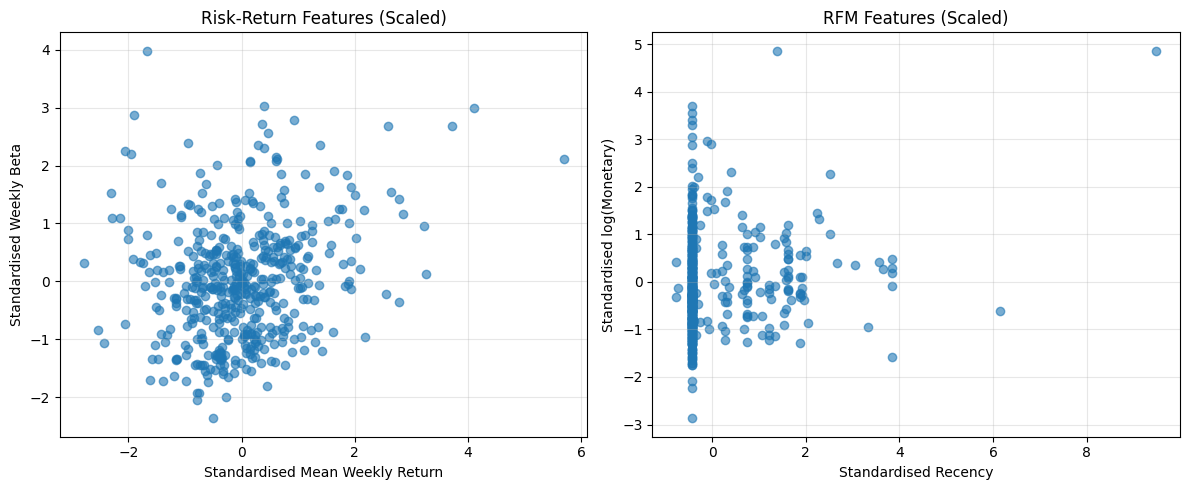

Prepared matrices saved.


In [ ]:
# =========================================================
# Task 2: Stock Segmentation
# =========================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Load final feature table
final = pd.read_csv("final_feature_table_task1.csv")
print("Original shape:", final.shape)
print(final.head())

# Create two separate matrices
risk_return = final[["ticker", "mean_weekly_return", "weekly_beta"]].copy()
rfm = final[["ticker", "Recency", "Frequency", "Monetary"]].copy()

print("Risk-Return matrix shape:", risk_return.shape)
print("RFM matrix shape:", rfm.shape)

# Keep only common tickers (should already be the same)
common = set(risk_return["ticker"]) & set(rfm["ticker"])
risk_return = risk_return[risk_return["ticker"].isin(common)].reset_index(drop=True)
rfm = rfm[rfm["ticker"].isin(common)].reset_index(drop=True)

print("Common shares used for clustering:", len(common))

# Inspect skewness
print("\n=== Risk-Return Skewness ===")
print(risk_return[["mean_weekly_return", "weekly_beta"]].skew())

print("\n=== RFM Skewness ===")
print(rfm[["Recency", "Frequency", "Monetary"]].skew())

# Log transform Monetary because of extreme skew
rfm["log_Monetary"] = np.log1p(rfm["Monetary"])

# Prepare numeric matrices
X_risk = risk_return[["mean_weekly_return", "weekly_beta"]].values
X_rfm = rfm[["Recency", "Frequency", "log_Monetary"]].values

# Standardise each matrix separately
scaler_risk = StandardScaler()
X_risk_scaled = scaler_risk.fit_transform(X_risk)

scaler_rfm = StandardScaler()
X_rfm_scaled = scaler_rfm.fit_transform(X_rfm)

print("\nRisk-Return scaled shape:", X_risk_scaled.shape)
print("RFM scaled shape:", X_rfm_scaled.shape)

# Quick visual check
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_risk_scaled[:, 0], X_risk_scaled[:, 1], alpha=0.6)
axes[0].set_title("Risk-Return Features (Scaled)")
axes[0].set_xlabel("Standardised Mean Weekly Return")
axes[0].set_ylabel("Standardised Weekly Beta")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X_rfm_scaled[:, 0], X_rfm_scaled[:, 2], alpha=0.6)
axes[1].set_title("RFM Features (Scaled)")
axes[1].set_xlabel("Standardised Recency")
axes[1].set_ylabel("Standardised log(Monetary)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Save prepared matrices
risk_return.to_csv("matrix_risk_return.csv", index=False)
rfm.to_csv("matrix_rfm.csv", index=False)
np.save("X_risk_scaled.npy", X_risk_scaled)
np.save("X_rfm_scaled.npy", X_rfm_scaled)

print("Prepared matrices saved.")

Risk-Return shape: (488, 2)
RFM shape: (488, 3)
Linkage matrices created.


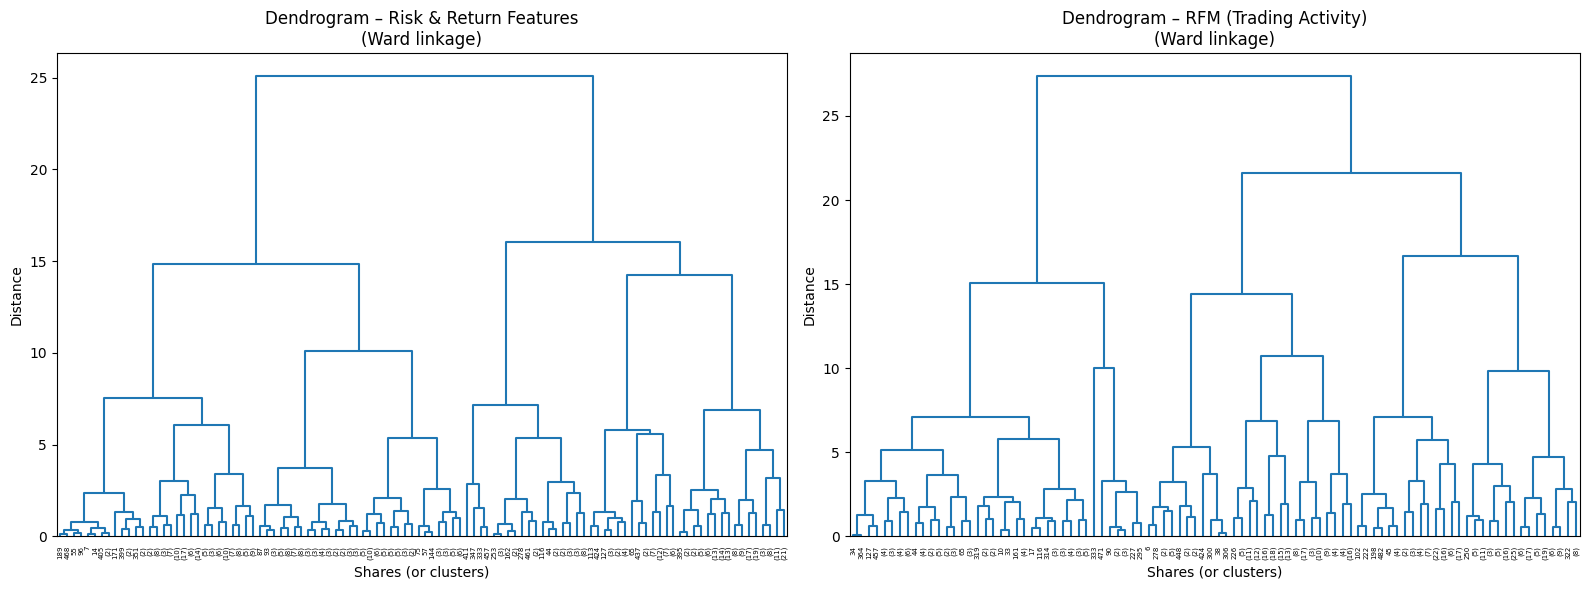


=== Risk-Return matrix ===
   k  silhouette                      cluster_sizes  min_size  max_size
0  2    0.289397                         [253, 235]       235       253
1  3    0.272652                     [253, 35, 200]        35       253
2  4    0.263656                [136, 117, 35, 200]        35       200
3  5    0.309048            [136, 117, 35, 48, 152]        35       152
4  6    0.311422         [136, 56, 61, 35, 48, 152]        35       152
5  7    0.309379     [16, 120, 56, 61, 35, 48, 152]        16       152
6  8    0.311451  [16, 120, 56, 61, 4, 31, 48, 152]         4       152

=== RFM matrix ===
   k  silhouette                    cluster_sizes  min_size  max_size
0  2    0.372392                        [85, 403]        85       403
1  3    0.260498                   [85, 180, 223]        85       223
2  4    0.250704               [85, 180, 86, 137]        85       180
3  5    0.269201           [75, 10, 180, 86, 137]        10       180
4  6    0.290714       [75

In [ ]:
# ---------------------------------------------------------
# 2.2 Agglomerative Clustering (Ward)
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score

# Load prepared data
risk_return = pd.read_csv("matrix_risk_return.csv")
rfm = pd.read_csv("matrix_rfm.csv")
X_risk_scaled = np.load("X_risk_scaled.npy")
X_rfm_scaled = np.load("X_rfm_scaled.npy")

print("Risk-Return shape:", X_risk_scaled.shape)
print("RFM shape:", X_rfm_scaled.shape)

# Create linkage matrices (Ward + Euclidean)
Z_risk = linkage(X_risk_scaled, method="ward", metric="euclidean")
Z_rfm = linkage(X_rfm_scaled, method="ward", metric="euclidean")

print("Linkage matrices created.")

# Plot dendrograms
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dendrogram(Z_risk, ax=axes[0], truncate_mode="level", p=6, color_threshold=0)
axes[0].set_title("Dendrogram – Risk & Return Features\n(Ward linkage)")
axes[0].set_xlabel("Shares (or clusters)")
axes[0].set_ylabel("Distance")

dendrogram(Z_rfm, ax=axes[1], truncate_mode="level", p=6, color_threshold=0)
axes[1].set_title("Dendrogram – RFM (Trading Activity)\n(Ward linkage)")
axes[1].set_xlabel("Shares (or clusters)")
axes[1].set_ylabel("Distance")

plt.tight_layout()
plt.savefig("dendrograms_task2_2.png", dpi=150, bbox_inches="tight")
plt.show()

# Evaluate different k values
def evaluate_hierarchical(X, Z, max_k=8):
    results = []
    for k in range(2, max_k + 1):
        labels = fcluster(Z, t=k, criterion="maxclust")
        sil = silhouette_score(X, labels)
        sizes = np.bincount(labels)[1:]  # ignore 0
        results.append({
            "k": k,
            "silhouette": sil,
            "cluster_sizes": sizes.tolist(),
            "min_size": sizes.min(),
            "max_size": sizes.max()
        })
    return pd.DataFrame(results)

print("\n=== Risk-Return matrix ===")
eval_risk = evaluate_hierarchical(X_risk_scaled, Z_risk)
print(eval_risk)

print("\n=== RFM matrix ===")
eval_rfm = evaluate_hierarchical(X_rfm_scaled, Z_rfm)
print(eval_rfm)

# Final choice of k (you can change these after looking at the results)
best_k_risk = 4
best_k_rfm = 3

labels_risk_agg = fcluster(Z_risk, t=best_k_risk, criterion="maxclust")
labels_rfm_agg = fcluster(Z_rfm, t=best_k_rfm, criterion="maxclust")

risk_return["cluster_agg"] = labels_risk_agg
rfm["cluster_agg"] = labels_rfm_agg

print("\nRisk-Return cluster sizes:")
print(risk_return["cluster_agg"].value_counts().sort_index())

print("\nRFM cluster sizes:")
print(rfm["cluster_agg"].value_counts().sort_index())

# Save results
risk_return.to_csv("risk_return_with_agg_clusters.csv", index=False)
rfm.to_csv("rfm_with_agg_clusters.csv", index=False)
print("\nCluster assignments saved.")

Data loaded.
=== Risk-Return matrix (K-means) ===
   k  silhouette     inertia                      cluster_sizes  min_size  \
0  2    0.376100  620.322274                         [331, 157]       157   
1  3    0.332974  449.504422                    [173, 121, 194]       121   
2  4    0.320776  363.050008                [164, 52, 146, 126]        52   
3  5    0.345104  293.232964            [133, 164, 106, 50, 35]        35   
4  6    0.330465  251.831240         [78, 36, 105, 87, 133, 49]        36   
5  7    0.356326  213.574743      [77, 80, 82, 23, 40, 43, 143]        23   
6  8    0.358087  190.708097  [57, 68, 23, 135, 73, 80, 15, 37]        15   

   max_size  
0       331  
1       194  
2       164  
3       164  
4       133  
5       143  
6       135  

=== RFM matrix (K-means) ===
   k  silhouette      inertia                      cluster_sizes  min_size  \
0  2    0.425222  1070.494216                          [420, 68]        68   
1  3    0.326051   800.061889      

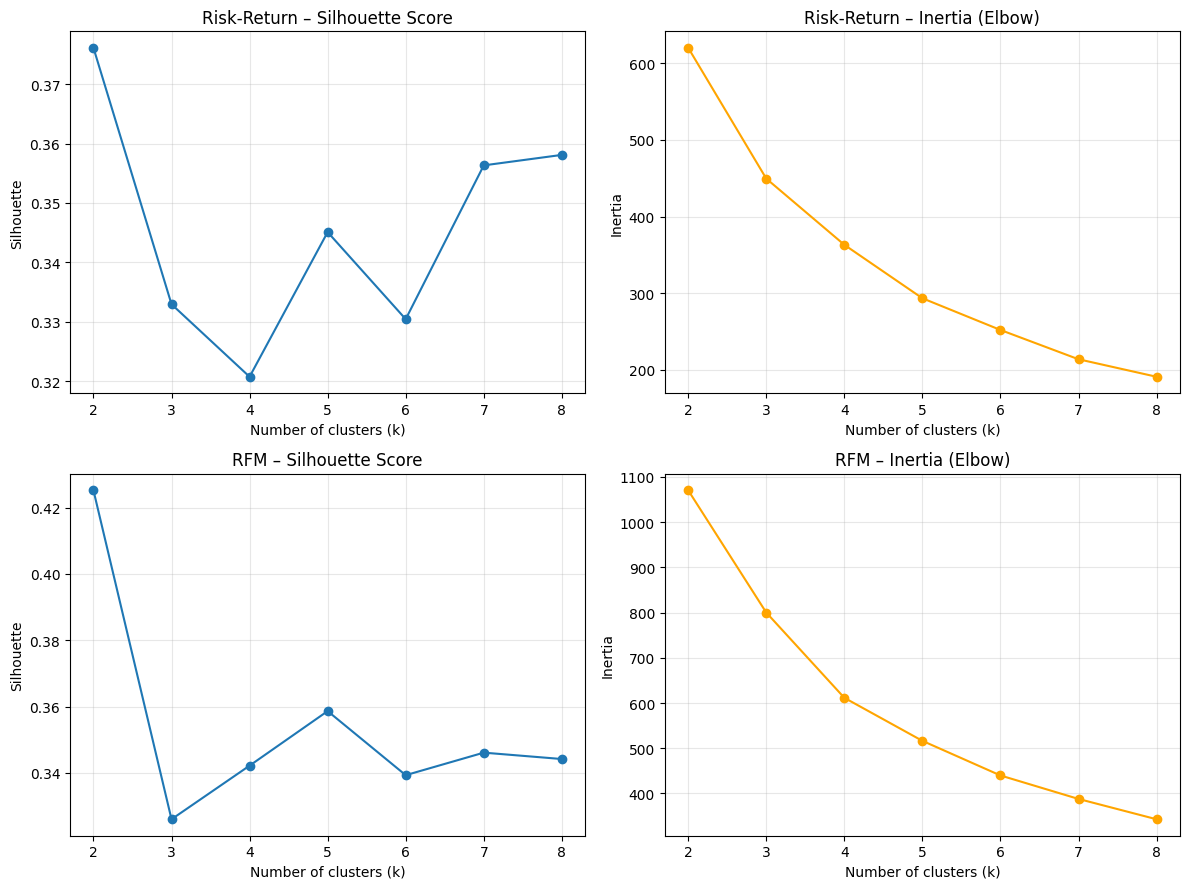


Risk-Return K-means cluster sizes:
cluster_kmeans
0    164
1     52
2    146
3    126
Name: count, dtype: int64

RFM K-means cluster sizes:
cluster_kmeans
0    275
1    150
2     63
Name: count, dtype: int64

K-means cluster assignments saved.


In [ ]:
# ---------------------------------------------------------
# 2.3 K-means Clustering
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load data
risk_return = pd.read_csv("matrix_risk_return.csv")
rfm = pd.read_csv("matrix_rfm.csv")
X_risk_scaled = np.load("X_risk_scaled.npy")
X_rfm_scaled = np.load("X_rfm_scaled.npy")

print("Data loaded.")

def evaluate_kmeans(X_scaled, max_k=8, random_state=42):
    results = []
    for k in range(2, max_k + 1):
        kmeans = KMeans(n_clusters=k, n_init=20, random_state=random_state)
        labels = kmeans.fit_predict(X_scaled)

        sil = silhouette_score(X_scaled, labels)
        inertia = kmeans.inertia_
        sizes = np.bincount(labels)

        results.append({
            "k": k,
            "silhouette": sil,
            "inertia": inertia,
            "cluster_sizes": sizes.tolist(),
            "min_size": sizes.min(),
            "max_size": sizes.max()
        })
    return pd.DataFrame(results)

print("=== Risk-Return matrix (K-means) ===")
eval_risk_km = evaluate_kmeans(X_risk_scaled)
print(eval_risk_km)

print("\n=== RFM matrix (K-means) ===")
eval_rfm_km = evaluate_kmeans(X_rfm_scaled)
print(eval_rfm_km)

# Plot silhouette and elbow
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Risk-Return
axes[0, 0].plot(eval_risk_km["k"], eval_risk_km["silhouette"], marker="o")
axes[0, 0].set_title("Risk-Return – Silhouette Score")
axes[0, 0].set_xlabel("Number of clusters (k)")
axes[0, 0].set_ylabel("Silhouette")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(eval_risk_km["k"], eval_risk_km["inertia"], marker="o", color="orange")
axes[0, 1].set_title("Risk-Return – Inertia (Elbow)")
axes[0, 1].set_xlabel("Number of clusters (k)")
axes[0, 1].set_ylabel("Inertia")
axes[0, 1].grid(True, alpha=0.3)

# RFM
axes[1, 0].plot(eval_rfm_km["k"], eval_rfm_km["silhouette"], marker="o")
axes[1, 0].set_title("RFM – Silhouette Score")
axes[1, 0].set_xlabel("Number of clusters (k)")
axes[1, 0].set_ylabel("Silhouette")
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(eval_rfm_km["k"], eval_rfm_km["inertia"], marker="o", color="orange")
axes[1, 1].set_title("RFM – Inertia (Elbow)")
axes[1, 1].set_xlabel("Number of clusters (k)")
axes[1, 1].set_ylabel("Inertia")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Final choice of k
best_k_risk = 4
best_k_rfm = 3

kmeans_risk = KMeans(n_clusters=best_k_risk, n_init=20, random_state=42)
labels_risk_km = kmeans_risk.fit_predict(X_risk_scaled)

kmeans_rfm = KMeans(n_clusters=best_k_rfm, n_init=20, random_state=42)
labels_rfm_km = kmeans_rfm.fit_predict(X_rfm_scaled)

risk_return["cluster_kmeans"] = labels_risk_km
rfm["cluster_kmeans"] = labels_rfm_km

print("\nRisk-Return K-means cluster sizes:")
print(risk_return["cluster_kmeans"].value_counts().sort_index())

print("\nRFM K-means cluster sizes:")
print(rfm["cluster_kmeans"].value_counts().sort_index())

# Save
risk_return.to_csv("risk_return_with_kmeans.csv", index=False)
rfm.to_csv("rfm_with_kmeans.csv", index=False)
print("\nK-means cluster assignments saved.")

  ticker  mean_weekly_return  weekly_beta  cluster_kmeans
0    MMM            0.001142     0.869079               2
1    AOS            0.001991     1.042805               3
2    ABT            0.000971     0.583543               2
3   ABBV            0.003749     0.425366               2
4    ACN            0.002376     1.143300               3
  ticker  Recency  Frequency      Monetary  log_Monetary  cluster_kmeans
0    MMM       11          4  2.599146e+10     23.981034               0
1    AOS       11          2  4.748980e+09     22.281196               0
2    ABT       11          1  3.523027e+10     24.285172               1
3   ABBV       11          3  6.837054e+10     24.948208               1
4    ACN       11          2  5.199430e+10     24.674400               1
=== Risk-Return Cluster Profiles (original units) ===
               mean_weekly_return                       weekly_beta          \
                             mean  median     std count        mean  median   
cl

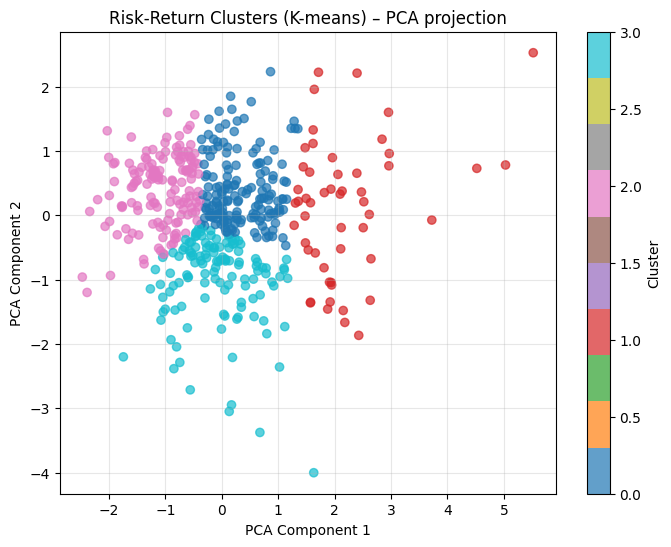

Explained variance (Risk-Return): [0.61 0.39]


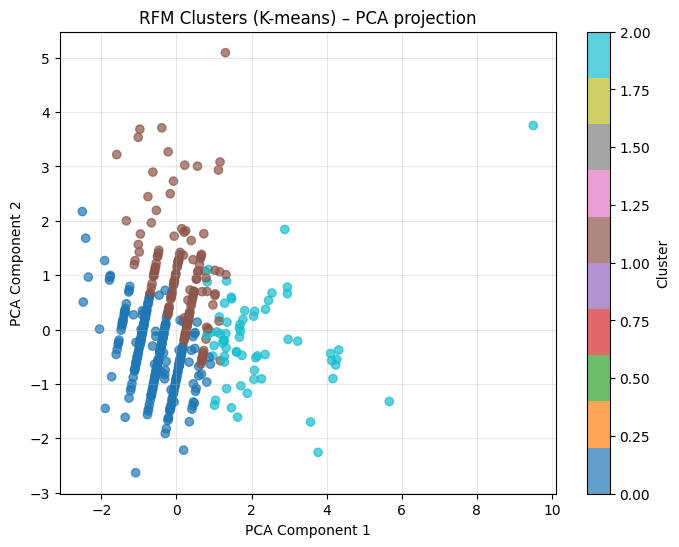

Explained variance (RFM): [0.458 0.336]


In [ ]:
# ---------------------------------------------------------
# 2.4 Cluster Profiles and Visualisation
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Load the K-means results
risk_return = pd.read_csv("risk_return_with_kmeans.csv")
rfm = pd.read_csv("rfm_with_kmeans.csv")

print(risk_return.head())
print(rfm.head())

# ----- Risk-Return Profiles -----
profile_risk = risk_return.groupby("cluster_kmeans").agg({
    "mean_weekly_return": ["mean", "median", "std", "count"],
    "weekly_beta": ["mean", "median", "std"]
}).round(4)

print("=== Risk-Return Cluster Profiles (original units) ===")
print(profile_risk)

# ----- RFM Profiles -----
profile_rfm = rfm.groupby("cluster_kmeans").agg({
    "Recency": ["mean", "median", "std", "count"],
    "Frequency": ["mean", "median", "std"],
    "Monetary": ["mean", "median"]
}).round(2)

print("\n=== RFM Cluster Profiles (original units) ===")
print(profile_rfm)

# ----- PCA Visualisation -----
X_risk_scaled = np.load("X_risk_scaled.npy")
X_rfm_scaled = np.load("X_rfm_scaled.npy")

# Risk-Return PCA
pca_risk = PCA(n_components=2, random_state=42)
X_risk_2d = pca_risk.fit_transform(X_risk_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_risk_2d[:, 0], X_risk_2d[:, 1],
                      c=risk_return["cluster_kmeans"], cmap="tab10", alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Risk-Return Clusters (K-means) – PCA projection")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.savefig("pca_risk_return_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

print("Explained variance (Risk-Return):", pca_risk.explained_variance_ratio_.round(3))

# RFM PCA
pca_rfm = PCA(n_components=2, random_state=42)
X_rfm_2d = pca_rfm.fit_transform(X_rfm_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_rfm_2d[:, 0], X_rfm_2d[:, 1],
                      c=rfm["cluster_kmeans"], cmap="tab10", alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("RFM Clusters (K-means) – PCA projection")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.savefig("pca_rfm_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

print("Explained variance (RFM):", pca_rfm.explained_variance_ratio_.round(3))

In [ ]:
from sklearn.metrics import adjusted_rand_score

# Load agglomerative labels
risk_agg = pd.read_csv("risk_return_with_agg_clusters.csv")

comparison = risk_return[["ticker", "cluster_kmeans"]].merge(
    risk_agg[["ticker", "cluster_agg"]], on="ticker"
)

contingency = pd.crosstab(comparison["cluster_kmeans"], comparison["cluster_agg"])
print("Contingency table (K-means vs Agglomerative) – Risk-Return:")
print(contingency)

ari = adjusted_rand_score(comparison["cluster_kmeans"], comparison["cluster_agg"])
print(f"\nAdjusted Rand Index: {ari:.3f}")

Contingency table (K-means vs Agglomerative) – Risk-Return:
cluster_agg      1   2   3    4
cluster_kmeans                 
0                3  24   5  132
1                0   0  30   22
2               53  93   0    0
3               80   0   0   46

Adjusted Rand Index: 0.377


Correlation matrix (R, F, log_Monetary):
              Recency  Frequency  log_Monetary
Recency         1.000     -0.346         0.152
Frequency      -0.346      1.000         0.013
log_Monetary    0.152      0.013         1.000


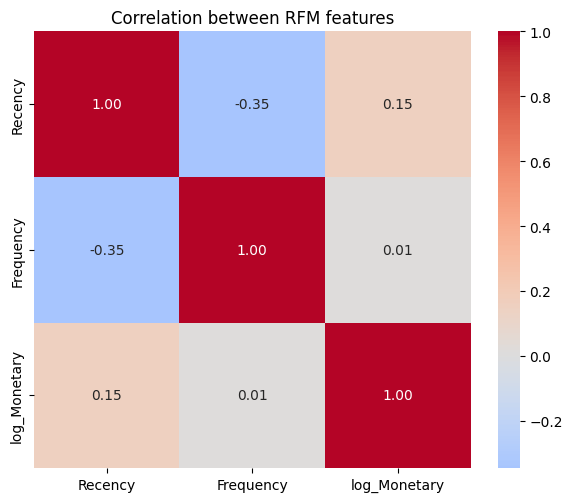

Original k: 3
Adjusted Rand Index (with vs without Monetary): 0.265

=== Average Monetary by original clusters ===
                     mean        median  count
cluster_agg                                   
1            4.836432e+10  2.124212e+10     85
2            6.993615e+10  3.424691e+10    180
3            1.101312e+10  1.013983e+10    223

=== Average Monetary by reduced clusters (R+F only) ===
                             mean        median  count
cluster_no_Monetary                                   
1                    4.630362e+10  2.013167e+10     89
2                    3.433790e+10  1.769899e+10    125
3                    3.920490e+10  1.476031e+10    274


In [ ]:
# ---------------------------------------------------------
# 2.5 Sensitivity Analysis
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score

# Load RFM matrix
rfm = pd.read_csv("matrix_rfm.csv")

# Ensure log_Monetary exists
if "log_Monetary" not in rfm.columns:
    rfm["log_Monetary"] = np.log1p(rfm["Monetary"])

# Correlation matrix
corr = rfm[["Recency", "Frequency", "log_Monetary"]].corr()
print("Correlation matrix (R, F, log_Monetary):")
print(corr.round(3))

# Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Correlation between RFM features")
plt.tight_layout()
plt.savefig("rfm_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# ----- Sensitivity test: remove Monetary -----
# Original solution (with Monetary)
rfm_full = pd.read_csv("rfm_with_agg_clusters.csv")
original_labels = rfm_full["cluster_agg"].values
best_k = rfm_full["cluster_agg"].nunique()
print("Original k:", best_k)

# Reduced feature matrix (Recency + Frequency only)
X_reduced = rfm[["Recency", "Frequency"]].values
scaler_reduced = StandardScaler()
X_reduced_scaled = scaler_reduced.fit_transform(X_reduced)

# Re-run Ward clustering
Z_reduced = linkage(X_reduced_scaled, method="ward", metric="euclidean")
labels_reduced = fcluster(Z_reduced, t=best_k, criterion="maxclust")

# Membership comparison
ari = adjusted_rand_score(original_labels, labels_reduced)
print(f"Adjusted Rand Index (with vs without Monetary): {ari:.3f}")

# Add the new labels
rfm_full["cluster_no_Monetary"] = labels_reduced

# Compare traded-value profiles
print("\n=== Average Monetary by original clusters ===")
print(rfm_full.groupby("cluster_agg")["Monetary"].agg(["mean", "median", "count"]).round(0))

print("\n=== Average Monetary by reduced clusters (R+F only) ===")
print(rfm_full.groupby("cluster_no_Monetary")["Monetary"].agg(["mean", "median", "count"]).round(0))